Notebook 4: Sentence-BERT models

Sentence Transformers maps text into fixed-size dense embeddings that can be used for classification.

imorting the necessary libraries

In [1]:
from pathlib import Path
from collections import Counter
import json
import random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Define project path

In [2]:
PROJECT_ROOT = Path.cwd()

# Use this instead if the notebook is inside a notebooks folder:
# PROJECT_ROOT = Path.cwd().parent

In [3]:
PROCESSED_DIR = PROJECT_ROOT / "processed_data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"
EMBEDDINGS_DIR = MODELS_DIR / "sbert_embeddings"

for directory in [
    MODELS_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    EMBEDDINGS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT)
print("Processed data directory:", PROCESSED_DIR)

Project root: c:\Users\Admin\Desktop\NLP\Data
Processed data directory: c:\Users\Admin\Desktop\NLP\Data\processed_data


Load the processed dataset

In [11]:
required_files = {
    "train": "train_utterances.csv",
    "validation": "validation_utterances.csv",
    "test": "test_utterances.csv"
}

found_files = {}

for split_name, filename in required_files.items():
    matches = list(CURRENT_DIR.rglob(filename))

    # Also search from the parent folder when the notebook
    # is stored inside a notebooks or Data folder.
    if not matches:
        matches = list(CURRENT_DIR.parent.rglob(filename))

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Could not find '{filename}' starting from:\n"
            f"{CURRENT_DIR}\n\n"
            "Check that Notebook 1 saved the processed datasets."
        )

    if len(matches) > 1:
        print(f"\nMultiple files found for {split_name}:")

        for index, match in enumerate(matches):
            print(index, ":", match)

        # Select the first match by default.
        # Change the index if the correct file is another one.
        selected_path = matches[0]
    else:
        selected_path = matches[0]

    found_files[split_name] = selected_path


TRAIN_PATH = found_files["train"]
VALIDATION_PATH = found_files["validation"]
TEST_PATH = found_files["test"]

print("\nSelected processed files:")
print("Train:", TRAIN_PATH)
print("Validation:", VALIDATION_PATH)
print("Test:", TEST_PATH)


Selected processed files:
Train: c:\Users\Admin\Desktop\NLP\processed_data\train_utterances.csv
Validation: c:\Users\Admin\Desktop\NLP\processed_data\validation_utterances.csv
Test: c:\Users\Admin\Desktop\NLP\processed_data\test_utterances.csv


In [12]:
train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

print("\nDatasets loaded successfully:")
print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())


Datasets loaded successfully:
Train shape: (87170, 21)
Validation shape: (8069, 21)
Test shape: (7740, 21)


,split,dialogue_id,turn_index,speaker_id,utterance,act_label,emotion_label,dialogue_length,utterance_length_words,utterance_length_characters,...,act_name,previous_1,previous_3,full_previous_context,text_no_context,text_context_1,text_context_3,text_full_context,text_shuffled_context,text_unrelated_context
0,train,train_00000,0,0,"Say , Jim , how about going for a few beers af...",3,0,10,14,58,...,directive,NaN,NaN,NaN,"[SPEAKER_A] Say , Jim , how about going for a ...","[CURRENT] [SPEAKER_A] Say , Jim , how about go...","[CURRENT] [SPEAKER_A] Say , Jim , how about go...","[CURRENT] [SPEAKER_A] Say , Jim , how about go...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_A] How about this sunday ? [SEP] [SPE...
1,train,train_00000,1,1,You know that is tempting but is really not go...,4,0,10,14,66,...,commissive,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] You know that is tempting but is r...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_A] You must be very busy these days ....
2,train,train_00000,2,0,What do you mean ? It will help us to relax .,2,0,10,12,45,...,question,[SPEAKER_B] You know that is tempting but is r...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_A] What do you mean ? It will help us...,[SPEAKER_B] You know that is tempting but is r...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] You know that is tempting but is r...,[SPEAKER_B] What is the completion date ? [SEP...
3,train,train_00000,3,1,Do you really think so ? I don't . It will jus...,2,0,10,23,96,...,question,[SPEAKER_A] What do you mean ? It will help us...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_A] What do you mean ? It will help us...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] Is it a Chinese New Year's gift or...
4,train,train_00000,4,0,I guess you are right.But what shall we do ? I...,2,0,10,18,80,...,question,[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_B] You know that is tempting but is r...,"[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_A] I guess you are right.But what sha...,[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_B] You know that is tempting but is r...,"[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_B] So is there a refrigerator ? [SEP]...


Defining the labels

In [13]:
LABEL_IDS = [0, 1, 2, 3, 4, 5, 6]

LABEL_NAMES = [
    "neutral",
    "anger",
    "disgust",
    "fear",
    "happiness",
    "sadness",
    "surprise"
]

ID_TO_LABEL = dict(
    zip(LABEL_IDS, LABEL_NAMES)
)

LABEL_TO_ID = {
    label: label_id
    for label_id, label in ID_TO_LABEL.items()
}

NUM_LABELS = len(LABEL_IDS)

Validating required columns

In [14]:
required_columns = {
    "dialogue_id",
    "turn_index",
    "utterance",
    "previous_3",
    "emotion_label",
    "emotion_name",
    "text_shuffled_context",
    "text_unrelated_context"
}

for split_name, dataframe in {
    "train": train_df,
    "validation": validation_df,
    "test": test_df
}.items():

    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{split_name} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    if dataframe["emotion_label"].isna().any():
        raise ValueError(
            f"{split_name} contains missing labels."
        )

    invalid_labels = set(
        dataframe["emotion_label"].unique()
    ) - set(LABEL_IDS)

    if invalid_labels:
        raise ValueError(
            f"{split_name} contains invalid labels: "
            f"{invalid_labels}"
        )

print("All required columns and labels are valid.")

All required columns and labels are valid.


Create raw context columns

Extracting context from combined text

In [15]:
def extract_context_only(value):
    """
    Extract dialogue history occurring before [CURRENT].

    Example:
    'history text [CURRENT] current utterance'
    becomes:
    'history text'
    """
    if pd.isna(value):
        return ""

    text = str(value).strip()

    if "[CURRENT]" in text:
        return text.split(
            "[CURRENT]",
            maxsplit=1
        )[0].strip()

    return text

applying it and late inspecting the results in the next cell.

In [16]:
for dataframe in [
    train_df,
    validation_df,
    test_df
]:
    dataframe["shuffled_context_only"] = (
        dataframe["text_shuffled_context"]
        .apply(extract_context_only)
    )

    dataframe["unrelated_context_only"] = (
        dataframe["text_unrelated_context"]
        .apply(extract_context_only)
    )

In [17]:
display(
    train_df[
        [
            "utterance",
            "previous_3",
            "shuffled_context_only",
            "unrelated_context_only"
        ]
    ].head(10)
)

,utterance,previous_3,shuffled_context_only,unrelated_context_only
0,"Say , Jim , how about going for a few beers af...",NaN,"[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_A] How about this sunday ? [SEP] [SPE...
1,You know that is tempting but is really not go...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_A] You must be very busy these days ....
2,What do you mean ? It will help us to relax .,"[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] You know that is tempting but is r...,[SPEAKER_B] What is the completion date ? [SEP...
3,Do you really think so ? I don't . It will jus...,"[SPEAKER_A] Say , Jim , how about going for a ...","[SPEAKER_A] Say , Jim , how about going for a ...",[SPEAKER_B] Is it a Chinese New Year's gift or...
4,I guess you are right.But what shall we do ? I...,[SPEAKER_B] You know that is tempting but is r...,[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_B] So is there a refrigerator ? [SEP]...
5,I suggest a walk over to the gym where we can ...,[SPEAKER_A] What do you mean ? It will help us...,[SPEAKER_A] What do you mean ? It will help us...,"[SPEAKER_B] You bet , Emily . Pull up a chair ..."
6,That's a good idea . I hear Mary and Sally oft...,[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_B] Do you really think so ? I don't ....,[SPEAKER_A] What's your email address ? [SEP] ...
7,"Sounds great to me ! If they are willing , we ...",[SPEAKER_A] I guess you are right.But what sha...,[SPEAKER_A] That's a good idea . I hear Mary a...,[SPEAKER_A] Show me the fastest way to get the...
8,Good.Let ' s go now .,[SPEAKER_B] I suggest a walk over to the gym w...,[SPEAKER_B] I suggest a walk over to the gym w...,[SPEAKER_A] Mr . : But not big enough . And he...
9,All right .,[SPEAKER_A] That's a good idea . I hear Mary a...,[SPEAKER_A] Good.Let ' s go now . [SEP] [SPEAK...,[SPEAKER_A] what are you listening to ? Is tha...


Defining the four experiments

Context experiment configuration

In [18]:
SBERT_EXPERIMENTS = {
    "no_context": {
        "current_column": "utterance",
        "context_column": None
    },

    "previous_3": {
        "current_column": "utterance",
        "context_column": "previous_3"
    },

    "shuffled_context": {
        "current_column": "utterance",
        "context_column": "shuffled_context_only"
    },

    "unrelated_context": {
        "current_column": "utterance",
        "context_column": "unrelated_context_only"
    }
}

for experiment_name, configuration in (
    SBERT_EXPERIMENTS.items()
):
    print(
        experiment_name,
        "→",
        configuration
    )

no_context → {'current_column': 'utterance', 'context_column': None}
previous_3 → {'current_column': 'utterance', 'context_column': 'previous_3'}
shuffled_context → {'current_column': 'utterance', 'context_column': 'shuffled_context_only'}
unrelated_context → {'current_column': 'utterance', 'context_column': 'unrelated_context_only'}


Loading Sentence-BERT

In [19]:
SBERT_MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

embedding_model = SentenceTransformer(
    SBERT_MODEL_NAME
)

EMBEDDING_DIMENSION = (
    embedding_model
    .get_sentence_embedding_dimension()
)

print("Loaded:", SBERT_MODEL_NAME)
print(
    "Embedding dimension:",
    EMBEDDING_DIMENSION
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2663.25it/s]


Loaded: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384


C:\Users\Admin\AppData\Local\Temp\ipykernel_28476\2805889303.py:11: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  .get_sentence_embedding_dimension()


Embedding functions

Define reusable encoding function

In [20]:
def encode_texts(
    text_series,
    cache_path=None,
    batch_size=128
):
    """
    Encode text using Sentence-BERT.

    If cache_path exists, embeddings are loaded instead
    of recomputed.
    """
    if (
        cache_path is not None
        and Path(cache_path).exists()
    ):
        embeddings = np.load(cache_path)

        print(
            "Loaded cached embeddings:",
            cache_path
        )

        return embeddings

    texts = (
        text_series
        .fillna("")
        .astype(str)
        .tolist()
    )

    embeddings = embedding_model.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    if embeddings.shape[0] != len(texts):
        raise ValueError(
            "Number of embeddings does not match "
            "number of input texts."
        )

    if not np.isfinite(embeddings).all():
        raise ValueError(
            "Embeddings contain NaN or infinite values."
        )

    if cache_path is not None:
        np.save(
            cache_path,
            embeddings
        )

        print(
            "Saved embeddings:",
            cache_path
        )

    return embeddings

Encoding the current utterance once


Current-utterance embeddings

In [21]:
print("Encoding training utterances...")

train_current_embeddings = encode_texts(
    train_df["utterance"],
    cache_path=(
        EMBEDDINGS_DIR
        / "train_current.npy"
    )
)

print("Encoding validation utterances...")

validation_current_embeddings = encode_texts(
    validation_df["utterance"],
    cache_path=(
        EMBEDDINGS_DIR
        / "validation_current.npy"
    )
)

print(
    "Training current embeddings:",
    train_current_embeddings.shape
)

print(
    "Validation current embeddings:",
    validation_current_embeddings.shape
)

Encoding training utterances...


Batches: 100%|██████████| 682/682 [12:48<00:00,  1.13s/it]


Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\train_current.npy
Encoding validation utterances...


Batches: 100%|██████████| 64/64 [00:49<00:00,  1.30it/s]

Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\validation_current.npy
Training current embeddings: (87170, 384)
Validation current embeddings: (8069, 384)


Encoding each context separately and creating feature matrices

Build four SBERT feature sets

In [22]:
FEATURE_SETS = {}

for experiment_name, configuration in (
    SBERT_EXPERIMENTS.items()
):
    print("\n" + "=" * 70)
    print("Preparing:", experiment_name)
    print("=" * 70)

    context_column = configuration[
        "context_column"
    ]

    # No-context experiment:
    # use only the current utterance embedding.
    if context_column is None:
        X_train_features = (
            train_current_embeddings
        )

        X_validation_features = (
            validation_current_embeddings
        )

    # Context experiments:
    # encode context separately and concatenate.
    else:
        train_context_embeddings = encode_texts(
            train_df[context_column],
            cache_path=(
                EMBEDDINGS_DIR
                / f"train_{experiment_name}_context.npy"
            )
        )

        validation_context_embeddings = encode_texts(
            validation_df[context_column],
            cache_path=(
                EMBEDDINGS_DIR
                / f"validation_{experiment_name}_context.npy"
            )
        )

        X_train_features = np.concatenate(
            [
                train_current_embeddings,
                train_context_embeddings
            ],
            axis=1
        )

        X_validation_features = np.concatenate(
            [
                validation_current_embeddings,
                validation_context_embeddings
            ],
            axis=1
        )

    FEATURE_SETS[experiment_name] = {
        "train": X_train_features,
        "validation": X_validation_features
    }

    print(
        "Train feature shape:",
        X_train_features.shape
    )

    print(
        "Validation feature shape:",
        X_validation_features.shape
    )


Preparing: no_context
Train feature shape: (87170, 384)
Validation feature shape: (8069, 384)

Preparing: previous_3


Batches: 100%|██████████| 682/682 [20:06<00:00,  1.77s/it] 


Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\train_previous_3_context.npy


Batches: 100%|██████████| 64/64 [01:37<00:00,  1.53s/it]


Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\validation_previous_3_context.npy
Train feature shape: (87170, 768)
Validation feature shape: (8069, 768)

Preparing: shuffled_context


Batches: 100%|██████████| 682/682 [22:59<00:00,  2.02s/it]  


... (3 outputs left out)

Batches: 100%|██████████| 682/682 [18:54<00:00,  1.66s/it]


Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\train_unrelated_context_context.npy


Batches: 100%|██████████| 64/64 [01:46<00:00,  1.67s/it]


Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\validation_unrelated_context_context.npy
Train feature shape: (87170, 768)
Validation feature shape: (8069, 768)


Preparing labels

Training and validation labels

In [23]:
y_train = (
    train_df["emotion_label"]
    .astype(int)
    .to_numpy()
)

y_validation = (
    validation_df["emotion_label"]
    .astype(int)
    .to_numpy()
)

print(
    "Training labels:",
    np.unique(
        y_train,
        return_counts=True
    )
)

print(
    "Validation labels:",
    np.unique(
        y_validation,
        return_counts=True
    )
)

Training labels: (array([0, 1, 2, 3, 4, 5, 6]), array([72143,   827,   303,   146, 11182,   969,  1600]))
Validation labels: (array([0, 1, 2, 3, 4, 5, 6]), array([7108,   77,    3,   11,  684,   79,  107]))


Create moderate class weights

The first fully balanced model overpredicted rare classes. I will compare three alternatives:

no weighting;
moderate square-root weighting;
fully balanced weighting.


Weight configurations

In [24]:
class_counts = Counter(y_train)

total_training_examples = len(y_train)
number_of_classes = len(LABEL_IDS)

fully_balanced_weight_values = {
    label: (
        total_training_examples
        / (
            number_of_classes
            * class_counts[label]
        )
    )
    for label in LABEL_IDS
}

sqrt_balanced_weights = {
    label: float(
        np.sqrt(weight)
    )
    for label, weight
    in fully_balanced_weight_values.items()
}

CLASS_WEIGHT_OPTIONS = {
    "none": None,
    "sqrt_balanced": sqrt_balanced_weights,
    "fully_balanced": "balanced"
}

print("Training class counts:")
print(class_counts)

print("\nModerate square-root weights:")
print(sqrt_balanced_weights)

Training class counts:
Counter({np.int64(0): 72143, np.int64(4): 11182, np.int64(6): 1600, np.int64(5): 969, np.int64(1): 827, np.int64(2): 303, np.int64(3): 146})

Moderate square-root weights:
{0: 0.4154678321810113, 1: 3.8804469292915913, 2: 6.41081417803317, 3: 9.235450290828489, 4: 1.0552971348506193, 5: 3.5848634229859413, 6: 2.7898092612731995}


Hyperparameter search

To keep the search meaningful but manageable, test three values of C.



Search configuration

In [25]:
C_VALUES = [
    0.1,
    1.0,
    5.0
]

print(
    "Total configurations:",
    (
        len(FEATURE_SETS)
        * len(CLASS_WEIGHT_OPTIONS)
        * len(C_VALUES)
    )
)

Total configurations: 36


Train and validate all configurations

In [34]:
search_results = []
trained_models = {}
validation_predictions = {}

for experiment_name, feature_data in (
    FEATURE_SETS.items()
):
    X_train_features = feature_data["train"]
    X_validation_features = (
        feature_data["validation"]
    )

    for weight_name, class_weight in (
        CLASS_WEIGHT_OPTIONS.items()
    ):
        for c_value in C_VALUES:

            configuration_name = (
                f"{experiment_name}"
                f"__{weight_name}"
                f"__C_{c_value}"
            )

            print(
                "\nTraining:",
                configuration_name
            )

            classifier = LogisticRegression(
                C=c_value,
                max_iter=3000,
                class_weight=class_weight,
                solver="lbfgs",
                random_state=SEED
            )

            classifier.fit(
                X_train_features,
                y_train
            )

            predictions = classifier.predict(
                X_validation_features
            )

            accuracy = accuracy_score(
                y_validation,
                predictions
            )

            balanced_accuracy = (
                balanced_accuracy_score(
                    y_validation,
                    predictions
                )
            )

            macro_f1 = f1_score(
                y_validation,
                predictions,
                labels=LABEL_IDS,
                average="macro",
                zero_division=0
            )

            weighted_f1 = f1_score(
                y_validation,
                predictions,
                labels=LABEL_IDS,
                average="weighted",
                zero_division=0
            )

            emotional_mask = (
                y_validation != 0
            )

            emotional_accuracy = (
                accuracy_score(
                    y_validation[
                        emotional_mask
                    ],
                    predictions[
                        emotional_mask
                    ]
                )
            )

            search_results.append({
                "configuration":
                    configuration_name,

                "context_setting":
                    experiment_name,

                "class_weight_setting":
                    weight_name,

                "C":
                    c_value,

                "accuracy":
                    accuracy,

                "balanced_accuracy":
                    balanced_accuracy,

                "macro_f1":
                    macro_f1,

                "weighted_f1":
                    weighted_f1,

                "accuracy_on_emotional_examples":
                    emotional_accuracy
            })

            trained_models[
                configuration_name
            ] = classifier

            validation_predictions[
                configuration_name
            ] = predictions


Training: no_context__none__C_0.1

Training: no_context__none__C_1.0

Training: no_context__none__C_5.0

Training: no_context__sqrt_balanced__C_0.1

Training: no_context__sqrt_balanced__C_1.0

Training: no_context__sqrt_balanced__C_5.0

Training: no_context__fully_balanced__C_0.1

Training: no_context__fully_balanced__C_1.0

Training: no_context__fully_balanced__C_5.0

Training: previous_3__none__C_0.1

Training: previous_3__none__C_1.0

Training: previous_3__none__C_5.0

Training: previous_3__sqrt_balanced__C_0.1

Training: previous_3__sqrt_balanced__C_1.0

Training: previous_3__sqrt_balanced__C_5.0

Training: previous_3__fully_balanced__C_0.1

Training: previous_3__fully_balanced__C_1.0

Training: previous_3__fully_balanced__C_5.0

Training: shuffled_context__none__C_0.1

Training: shuffled_context__none__C_1.0

Training: shuffled_context__none__C_5.0

Training: shuffled_context__sqrt_balanced__C_0.1

Training: shuffled_context__sqrt_balanced__C_1.0

Training: shuffled_context__sqrt

Reviewing search results

Complete results table

In [35]:
sbert_search_results_df = (
    pd.DataFrame(search_results)
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    sbert_search_results_df
    .head(20)
    .round(4)
)

sbert_search_results_df.to_csv(
    TABLES_DIR
    / "sbert_validation_hyperparameter_search.csv",
    index=False
)

,configuration,context_setting,class_weight_setting,C,accuracy,balanced_accuracy,macro_f1,weighted_f1,accuracy_on_emotional_examples
0,shuffled_context__sqrt_balanced__C_1.0,shuffled_context,sqrt_balanced,1.0,0.8614,0.4153,0.3703,0.8724,0.5765
1,previous_3__sqrt_balanced__C_1.0,previous_3,sqrt_balanced,1.0,0.8611,0.4136,0.3680,0.8721,0.5713
2,shuffled_context__sqrt_balanced__C_5.0,shuffled_context,sqrt_balanced,5.0,0.8534,0.4236,0.3626,0.8678,0.5765
3,shuffled_context__sqrt_balanced__C_0.1,shuffled_context,sqrt_balanced,0.1,0.8716,0.3700,0.3622,0.8767,0.5453
4,previous_3__sqrt_balanced__C_0.1,previous_3,sqrt_balanced,0.1,0.8740,0.3671,0.3615,0.8783,0.5401
5,previous_3__sqrt_balanced__C_5.0,previous_3,sqrt_balanced,5.0,0.8545,0.4124,0.3553,0.8687,0.5734
6,unrelated_context__sqrt_balanced__C_0.1,unrelated_context,sqrt_balanced,0.1,0.8699,0.3597,0.3525,0.8749,0.5286
7,no_context__sqrt_balanced__C_0.1,no_context,sqrt_balanced,0.1,0.8696,0.3589,0.3512,0.8749,0.5297
8,no_context__sqrt_balanced__C_1.0,no_context,sqrt_balanced,1.0,0.8576,0.3934,0.3497,0.8698,0.5682
9,unrelated_context__sqrt_balanced__C_1.0,unrelated_context,sqrt_balanced,1.0,0.8557,0.3903,0.3454,0.8684,0.5619


NB: Accuracy on emotional examples = micro_f1_excluding_neutral

Best model for each context setting.

In [36]:
best_per_context_df = (
    sbert_search_results_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .groupby(
        "context_setting",
        as_index=False
    )
    .first()
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    best_per_context_df[
        [
            "context_setting",
            "class_weight_setting",
            "C",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "weighted_f1",
            "accuracy_on_emotional_examples"
        ]
    ].round(4)
)

best_per_context_df.to_csv(
    TABLES_DIR
    / "best_sbert_model_per_context.csv",
    index=False
)

,context_setting,class_weight_setting,C,accuracy,balanced_accuracy,macro_f1,weighted_f1,accuracy_on_emotional_examples
0,shuffled_context,sqrt_balanced,1.0,0.8614,0.4153,0.3703,0.8724,0.5765
1,previous_3,sqrt_balanced,1.0,0.8611,0.4136,0.3680,0.8721,0.5713
2,unrelated_context,sqrt_balanced,0.1,0.8699,0.3597,0.3525,0.8749,0.5286
3,no_context,sqrt_balanced,0.1,0.8696,0.3589,0.3512,0.8749,0.5297


Plot best Macro-F1 for each context

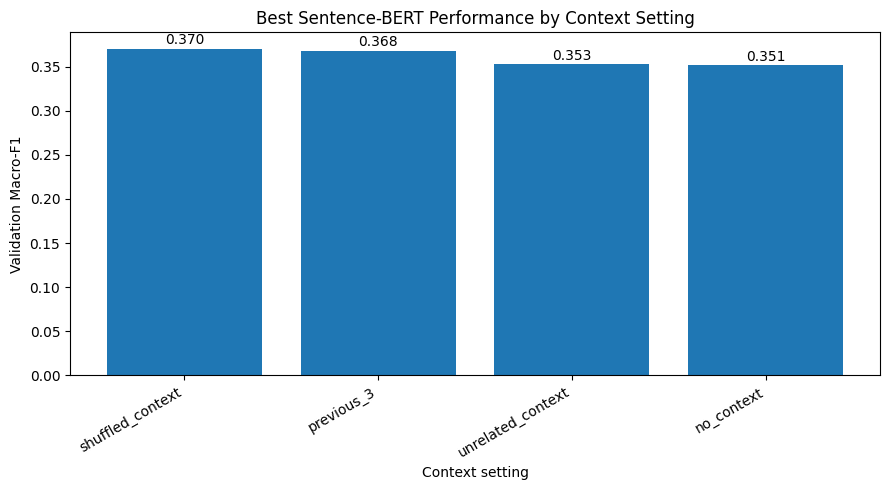

In [37]:
plt.figure(figsize=(9, 5))

positions = np.arange(
    len(best_per_context_df)
)

plt.bar(
    positions,
    best_per_context_df["macro_f1"]
)

plt.xticks(
    positions,
    best_per_context_df["context_setting"],
    rotation=30,
    ha="right"
)

plt.xlabel("Context setting")
plt.ylabel("Validation Macro-F1")

plt.title(
    "Best Sentence-BERT Performance "
    "by Context Setting"
)

for index, value in enumerate(
    best_per_context_df["macro_f1"]
):
    plt.text(
        index,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "sbert_best_macro_f1_by_context.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Selecting the overall best SBERT model


Automatic best-model selection

In [38]:
best_row = sbert_search_results_df.iloc[0]

BEST_CONFIGURATION = best_row[
    "configuration"
]

BEST_CONTEXT_SETTING = best_row[
    "context_setting"
]

BEST_CLASS_WEIGHT_SETTING = best_row[
    "class_weight_setting"
]

BEST_C = float(
    best_row["C"]
)

best_sbert_model = trained_models[
    BEST_CONFIGURATION
]

best_validation_predictions = (
    validation_predictions[
        BEST_CONFIGURATION
    ]
)

print("BEST SBERT CONFIGURATION")
print("=" * 60)

print(
    "Configuration:",
    BEST_CONFIGURATION
)

print(
    "Context setting:",
    BEST_CONTEXT_SETTING
)

print(
    "Class weighting:",
    BEST_CLASS_WEIGHT_SETTING
)

print(
    "C:",
    BEST_C
)

print(
    "Validation accuracy:",
    f"{best_row['accuracy']:.4f}"
)

print(
    "Validation Macro-F1:",
    f"{best_row['macro_f1']:.4f}"
)

print(
    "Validation weighted-F1:",
    f"{best_row['weighted_f1']:.4f}"
)

BEST SBERT CONFIGURATION
Configuration: shuffled_context__sqrt_balanced__C_1.0
Context setting: shuffled_context
Class weighting: sqrt_balanced
C: 1.0
Validation accuracy: 0.8614
Validation Macro-F1: 0.3703
Validation weighted-F1: 0.8724


Evaluating the best validation model

Per-class classification report

In [39]:
best_validation_report = (
    classification_report(
        y_validation,
        best_validation_predictions,
        labels=LABEL_IDS,
        target_names=LABEL_NAMES,
        output_dict=True,
        zero_division=0
    )
)

best_validation_report_df = pd.DataFrame(
    best_validation_report
).transpose()

display(
    best_validation_report_df.round(4)
)

best_validation_report_df.to_csv(
    TABLES_DIR
    / "best_sbert_validation_classification_report.csv"
)

,precision,recall,f1-score,support
neutral,0.9505,0.9000,0.9246,7108.0000
anger,0.3190,0.4805,0.3834,77.0000
disgust,0.0000,0.0000,0.0000,3.0000
fear,0.1000,0.1818,0.1290,11.0000
happiness,0.4797,0.6579,0.5549,684.0000
sadness,0.2051,0.3038,0.2449,79.0000
surprise,0.3306,0.3832,0.3550,107.0000
accuracy,0.8614,0.8614,0.8614,0.8614
macro avg,0.3407,0.4153,0.3703,8069.0000
weighted avg,0.8876,0.8614,0.8724,8069.0000


Noemalized confusion matrix

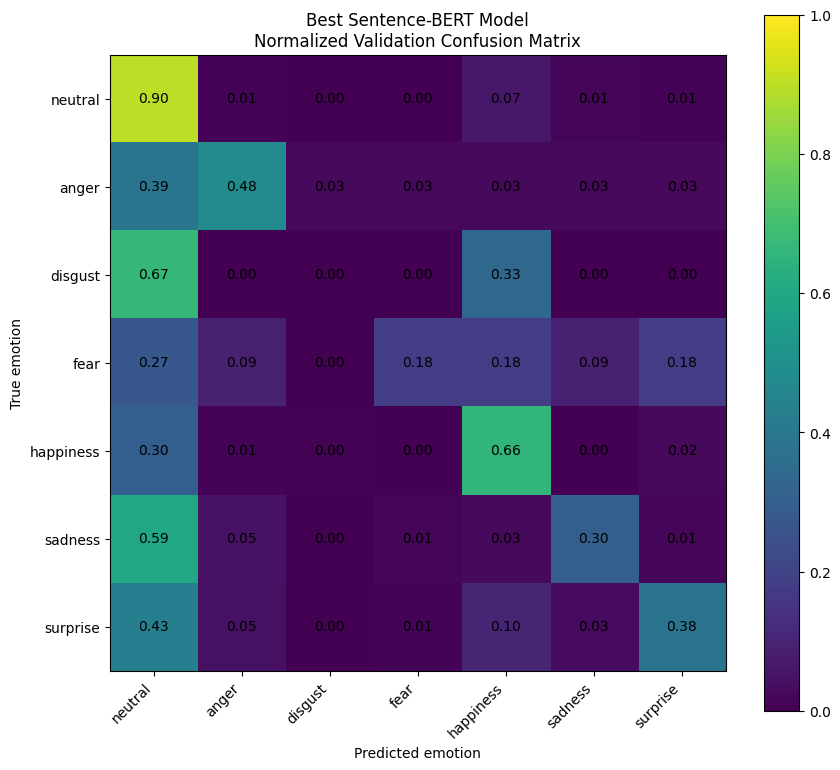

In [40]:
normalized_confusion_matrix = confusion_matrix(
    y_validation,
    best_validation_predictions,
    labels=LABEL_IDS,
    normalize="true"
)

fig, ax = plt.subplots(
    figsize=(9, 8)
)

image = ax.imshow(
    normalized_confusion_matrix,
    vmin=0,
    vmax=1
)

ax.set_xticks(
    range(len(LABEL_NAMES))
)

ax.set_xticklabels(
    LABEL_NAMES,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(LABEL_NAMES))
)

ax.set_yticklabels(
    LABEL_NAMES
)

for row in range(
    normalized_confusion_matrix.shape[0]
):
    for column in range(
        normalized_confusion_matrix.shape[1]
    ):
        ax.text(
            column,
            row,
            (
                f"{normalized_confusion_matrix[row, column]:.2f}"
            ),
            ha="center",
            va="center"
        )

ax.set_title(
    "Best Sentence-BERT Model\n"
    "Normalized Validation Confusion Matrix"
)

ax.set_xlabel("Predicted emotion")
ax.set_ylabel("True emotion")

fig.colorbar(image)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "best_sbert_validation_normalized_cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Checking prediction distribution

True versus predicted class counts

In [41]:
true_counts = (
    pd.Series(y_validation)
    .value_counts()
    .sort_index()
)

predicted_counts = (
    pd.Series(
        best_validation_predictions
    )
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "label": LABEL_IDS,
    "emotion": LABEL_NAMES,

    "true_count": [
        true_counts.get(label, 0)
        for label in LABEL_IDS
    ],

    "predicted_count": [
        predicted_counts.get(label, 0)
        for label in LABEL_IDS
    ]
})

distribution_df[
    "predicted_minus_true"
] = (
    distribution_df["predicted_count"]
    - distribution_df["true_count"]
)

display(distribution_df)

distribution_df.to_csv(
    TABLES_DIR
    / "best_sbert_prediction_distribution.csv",
    index=False
)

,label,emotion,true_count,predicted_count,predicted_minus_true
0,0,neutral,7108,6730,-378
1,1,anger,77,116,39
2,2,disgust,3,24,21
3,3,fear,11,20,9
4,4,happiness,684,938,254
5,5,sadness,79,117,38
6,6,surprise,107,124,17


Saving validation predictions

Prediction dataframe

In [42]:
validation_prediction_df = validation_df[
    [
        "dialogue_id",
        "turn_index",
        "previous_3",
        "utterance",
        "emotion_label",
        "emotion_name"
    ]
].copy()

validation_prediction_df[
    "predicted_label"
] = best_validation_predictions

validation_prediction_df[
    "predicted_emotion"
] = (
    validation_prediction_df[
        "predicted_label"
    ].map(ID_TO_LABEL)
)

validation_prediction_df[
    "correct"
] = (
    validation_prediction_df[
        "emotion_label"
    ]
    == validation_prediction_df[
        "predicted_label"
    ]
)

validation_prediction_df[
    "selected_context_setting"
] = BEST_CONTEXT_SETTING

validation_prediction_df.to_csv(
    PREDICTIONS_DIR
    / "best_sbert_validation_predictions.csv",
    index=False
)

Qualitative error analysis

In [43]:
errors_df = validation_prediction_df.loc[
    ~validation_prediction_df["correct"]
].copy()

number_of_errors_to_sample = min(
    20,
    len(errors_df)
)

error_examples_df = errors_df.sample(
    n=number_of_errors_to_sample,
    random_state=SEED
)

error_examples_df[
    "manual_comment"
] = ""

display(
    error_examples_df[
        [
            "previous_3",
            "utterance",
            "emotion_name",
            "predicted_emotion",
            "manual_comment"
        ]
    ]
)

error_examples_df.to_csv(
    TABLES_DIR
    / "best_sbert_error_examples.csv",
    index=False
)

,previous_3,utterance,emotion_name,predicted_emotion,manual_comment
7189,[SPEAKER_A] Please wait a moment . I'll make o...,Thank you .,neutral,happiness,
644,"[SPEAKER_B] I am sorry , we don't know the ext...","Yes , I will . Thanks a lot . Bye !",neutral,happiness,
3430,[SPEAKER_A] What a terrible house !,"I'm sick of it , too .",neutral,disgust,
5033,NaN,I miss grandma . I dreamed about her yesterday .,sadness,neutral,
5575,"[SPEAKER_A] Hi , John . [SEP] [SPEAKER_B] Oh ,...","Oh , no problem .",neutral,happiness,
5654,NaN,"Yes , emergency . There is a huge fire here .",fear,neutral,
3695,[SPEAKER_A] You look great ! How do you stay i...,"Wow , it sounds like a lot of work . I guess I...",neutral,happiness,
4949,[SPEAKER_A] Smells good ! What ’ s for breakfa...,"Kind of , so I made scrambled and soft boiled ...",happiness,neutral,
878,"[SPEAKER_B] No , I want the fish . [SEP] [SPEA...",Perhaps you'd enjoy the lamb .,neutral,happiness,
6913,NaN,"Oh , gosh ! I feel everything around me is aga...",sadness,anger,


**Overview:** 
Table shows sampled validation examples where predicted emotion ≠ gold emotion.

- **Major pattern:** Many `neutral` utterances are misclassified as `happiness` — the model leans toward predicting `happiness`.  

- **Other confusions:** Instances of `sadness`/`fear` → `neutral` and `anger` → `disgust`/`surprise` appear, indicating class-specific confusion. 

- **Likely causes:** short or ambiguous utterances, missing context (`previous_3` often NaN), and class imbalance biasing predictions. 

- **Impact:** Emotional-class recall suffers (false negatives), while `happiness` false positives increase, hurting macro-F1 for emotional classes. 


Save the selected model and configuration
Save model

In [44]:
BEST_MODEL_PATH = (
    MODELS_DIR
    / "best_sbert_logistic_regression.joblib"
)

joblib.dump(
    best_sbert_model,
    BEST_MODEL_PATH
)

print(
    "Best model saved to:",
    BEST_MODEL_PATH
)

Best model saved to: c:\Users\Admin\Desktop\NLP\Data\models\best_sbert_logistic_regression.joblib


saving configurations

In [45]:
best_configuration = {
    "sbert_model":
        SBERT_MODEL_NAME,

    "configuration":
        BEST_CONFIGURATION,

    "context_setting":
        BEST_CONTEXT_SETTING,

    "class_weight_setting":
        BEST_CLASS_WEIGHT_SETTING,

    "C":
        BEST_C,

    "validation_accuracy":
        float(best_row["accuracy"]),

    "validation_balanced_accuracy":
        float(
            best_row["balanced_accuracy"]
        ),

    "validation_macro_f1":
        float(best_row["macro_f1"]),

    "validation_weighted_f1":
        float(best_row["weighted_f1"]),

    "random_seed":
        SEED
}

CONFIGURATION_PATH = (
    MODELS_DIR
    / "best_sbert_configuration.json"
)

with open(
    CONFIGURATION_PATH,
    "w",
    encoding="utf-8"
) as configuration_file:
    json.dump(
        best_configuration,
        configuration_file,
        indent=2
    )

print(
    "Configuration saved to:",
    CONFIGURATION_PATH
)

Configuration saved to: c:\Users\Admin\Desktop\NLP\Data\models\best_sbert_configuration.json


Final test evaluation


Encode test utterances

In [46]:
test_current_embeddings = encode_texts(
    test_df["utterance"],
    cache_path=(
        EMBEDDINGS_DIR
        / "test_current.npy"
    )
)

Batches: 100%|██████████| 61/61 [00:39<00:00,  1.53it/s]

Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\test_current.npy


Builing test features matching the selected context

In [47]:
best_context_column = (
    SBERT_EXPERIMENTS[
        BEST_CONTEXT_SETTING
    ]["context_column"]
)

if best_context_column is None:
    X_test_best = (
        test_current_embeddings
    )

else:
    test_context_embeddings = encode_texts(
        test_df[best_context_column],
        cache_path=(
            EMBEDDINGS_DIR
            / (
                f"test_{BEST_CONTEXT_SETTING}"
                "_context.npy"
            )
        )
    )

    X_test_best = np.concatenate(
        [
            test_current_embeddings,
            test_context_embeddings
        ],
        axis=1
    )

print(
    "Final test feature shape:",
    X_test_best.shape
)

Batches: 100%|██████████| 61/61 [01:46<00:00,  1.75s/it]


Saved embeddings: c:\Users\Admin\Desktop\NLP\Data\models\sbert_embeddings\test_shuffled_context_context.npy
Final test feature shape: (7740, 768)


Final Test prediction

In [48]:
y_test = (
    test_df["emotion_label"]
    .astype(int)
    .to_numpy()
)

test_predictions = best_sbert_model.predict(
    X_test_best
)

final_test_metrics = {
    "model":
        "SBERT + Logistic Regression",

    "selected_configuration":
        BEST_CONFIGURATION,

    "selected_context":
        BEST_CONTEXT_SETTING,

    "accuracy":
        accuracy_score(
            y_test,
            test_predictions
        ),

    "balanced_accuracy":
        balanced_accuracy_score(
            y_test,
            test_predictions
        ),

    "macro_f1":
        f1_score(
            y_test,
            test_predictions,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        ),

    "weighted_f1":
        f1_score(
            y_test,
            test_predictions,
            labels=LABEL_IDS,
            average="weighted",
            zero_division=0
        )
}

print("FINAL SBERT TEST RESULTS")
print("=" * 60)

print(
    pd.Series(final_test_metrics)
)

FINAL SBERT TEST RESULTS
model                                SBERT + Logistic Regression
selected_configuration    shuffled_context__sqrt_balanced__C_1.0
selected_context                                shuffled_context
accuracy                                                0.802067
balanced_accuracy                                       0.480793
macro_f1                                                0.411672
weighted_f1                                             0.813114
dtype: object


Final test classification report

In [49]:
final_test_report = classification_report(
    y_test,
    test_predictions,
    labels=LABEL_IDS,
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

final_test_report_df = pd.DataFrame(
    final_test_report
).transpose()

display(
    final_test_report_df.round(4)
)

pd.DataFrame(
    [final_test_metrics]
).to_csv(
    TABLES_DIR
    / "final_sbert_test_metrics.csv",
    index=False
)

final_test_report_df.to_csv(
    TABLES_DIR
    / "final_sbert_test_classification_report.csv"
)

,precision,recall,f1-score,support
neutral,0.9101,0.8616,0.8852,6321.0000
anger,0.2616,0.3814,0.3103,118.0000
disgust,0.2000,0.2979,0.2393,47.0000
fear,0.1667,0.3529,0.2264,17.0000
happiness,0.5410,0.5898,0.5643,1019.0000
sadness,0.2514,0.4510,0.3228,102.0000
surprise,0.2717,0.4310,0.3333,116.0000
accuracy,0.8021,0.8021,0.8021,0.8021
macro avg,0.3718,0.4808,0.4117,7740.0000
weighted avg,0.8274,0.8021,0.8131,7740.0000


Saving the final test predictions

In [50]:
test_prediction_df = test_df[
    [
        "dialogue_id",
        "turn_index",
        "previous_3",
        "utterance",
        "emotion_label",
        "emotion_name"
    ]
].copy()

test_prediction_df[
    "predicted_label"
] = test_predictions

test_prediction_df[
    "predicted_emotion"
] = (
    test_prediction_df[
        "predicted_label"
    ].map(ID_TO_LABEL)
)

test_prediction_df[
    "correct"
] = (
    test_prediction_df[
        "emotion_label"
    ]
    == test_prediction_df[
        "predicted_label"
    ]
)

test_prediction_df[
    "selected_context_setting"
] = BEST_CONTEXT_SETTING

test_prediction_df.to_csv(
    PREDICTIONS_DIR
    / "final_sbert_test_predictions.csv",
    index=False
)

print(
    "Final predictions saved successfully."
)

Final predictions saved successfully.


### Short Summary

Sentence-BERT was used as a frozen embedding model, while Logistic Regression performed the final emotion classification. Four context settings were evaluated: **no context, previous three turns, shuffled context, and unrelated context**. The best validation model used **shuffled context**, **square-root balanced class weights**, and **C = 1.0**, achieving the highest validation Macro-F1.

Compared with the no-context model, adding dialogue context provided a **small improvement**, while shuffled and correctly ordered context produced very similar results, suggesting that the frozen Sentence-BERT embeddings captured semantic context but did not effectively exploit dialogue order. The model performed best on the **neutral** and **happiness** classes, whereas **fear** and **disgust** remained the most difficult because of severe class imbalance.

On the **held-out test set**, the selected model achieved **80.21% accuracy**, **41.17% Macro-F1**, and **81.31% Weighted-F1**, demonstrating good generalization to unseen conversations. Overall, Sentence-BERT provides a strong embedding-based baseline, but its limitations in modelling conversational context motivate the use of a fine-tuned transformer model in the next stage of the project.
